# Analysis Toolbox Demo

This notebook demonstrates post-fit analysis helpers: ROI statistics, ROI timecourses, and group-level comparisons. The example synthesizes a small batch study, so it runs without bundled datasets.


In [1]:
from pathlib import Path
import json
import shutil

import numpy as np
import matplotlib.pyplot as plt

from mrax.analysis import ROI, collect_roi_stats, extract_timecourse, analyze_groups
from mrax.core.batch import run_batch_studies
from mrax.core.synthetic import make_example_suite
from mrax.data_struct import Quantity, Study, load_study_results


## Run a small batch study

Create four synthetic subjects, fit a T1 inversion-recovery model for each subject, and persist the generated results under `tmp/analysis_toolbox_demo`.


In [2]:
demo_root = Path.cwd() / "tmp" / "analysis_toolbox_demo"
inputs_root = demo_root / "inputs"
outputs_root = demo_root / "outputs"

for path in (inputs_root, outputs_root):
    if path.exists():
        shutil.rmtree(path)
    path.mkdir(parents=True, exist_ok=True)

subjects = [
    ("control_01", 0, "control"),
    ("control_02", 1, "control"),
    ("treated_01", 2, "treated"),
    ("treated_02", 3, "treated"),
]

for name, seed, group in subjects:
    study_dir = inputs_root / name
    study_dir.mkdir(parents=True, exist_ok=True)
    (study_dir / "config.json").write_text(json.dumps({"seed": seed, "group": group}))

def loader(study_dir: Path):
    cfg = json.loads((study_dir / "config.json").read_text())
    examples = make_example_suite(noise_level=0.03, seed=cfg["seed"])[:1]
    study_globals = {"field_strength_mhz": Quantity(400.0, "MHz")}
    return Study.from_examples(examples, study_globals=study_globals), {"config": cfg}

summaries = run_batch_studies(
    studies_root=inputs_root,
    study_loader=loader,
    output_root=outputs_root,
    analysis_kwargs={"num_steps": 3, "step_size": 0.02},
)
summaries


[{'study_name': 'control_01',
  'manifest_path': PosixPath('tmp/analysis_toolbox_demo/outputs/control_01/study_manifest.json'),
  'results': [{'name': 't1_ir',
    'model': 't1_ir',
    'fields': {'amplitude': Quantity(values=Array([[0.68209094, 0.68224174, 0.6835417 , 0.6861043 , 0.68232936,
             0.6828738 , 0.6820199 , 0.6835348 , 0.6820076 , 0.6838535 ,
             0.6821099 , 0.68606627, 0.6823191 , 0.68227303, 0.6821362 ,
             0.68248117],
            [0.7430966 , 0.7430551 , 0.7426947 , 0.715351  , 0.68526715,
             0.68195516, 0.68180376, 0.68175155, 0.6817051 , 0.6817301 ,
             0.68183374, 0.6818913 , 0.68316513, 0.68289655, 0.72453564,
             0.6853528 ],
            [0.7431159 , 0.74310654, 0.7431274 , 0.7429968 , 0.6829904 ,
             0.6817659 , 0.6816841 , 0.6816497 , 0.681646  , 0.6816479 ,
             0.6816673 , 0.681732  , 0.6820277 , 0.6840507 , 0.7336869 ,
             0.7423251 ],
            [0.743139  , 0.74313307, 0.74311

## ROI statistics for parameter maps

Load one subject's manifest and extract ROI statistics from the fitted maps.


In [3]:
manifest = summaries[0]["manifest_path"]
data = load_study_results(manifest)
exp = data["experiments"]["t1_ir"]
maps = exp["fitted_maps"]
mr_image = exp["mr_image"]

mask = np.zeros(mr_image.shape[-2:], dtype=bool)
mask[4:12, 4:12] = True
roi = ROI("center", mask)

rows = collect_roi_stats(maps, [roi], stats=("mean", "variance"))
rows


[{'map': 'amplitude',
  'roi': 'center',
  'stat': 'mean',
  'value': 0.7074053883552551,
  'unit': '1'},
 {'map': 'amplitude',
  'roi': 'center',
  'stat': 'variance',
  'value': 0.0008956128731369972,
  'unit': '1'},
 {'map': 't1',
  'roi': 'center',
  'stat': 'mean',
  'value': 2452.32373046875,
  'unit': 'ms'},
 {'map': 't1',
  'roi': 'center',
  'stat': 'variance',
  'value': 137.02313232421875,
  'unit': 'ms'}]

## ROI timecourse

Reduce the ROI in the raw image stack to a timecourse.


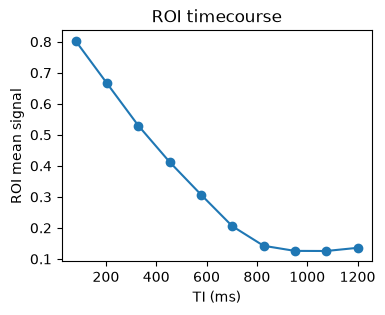

In [4]:
timecourse = extract_timecourse(mr_image, roi, stat="mean")
ti = exp["observables"].get("TI")
ti_vals = np.asarray(ti.values) if ti is not None else np.arange(timecourse.shape[0])

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(ti_vals, timecourse, marker="o")
ax.set_xlabel("TI (ms)")
ax.set_ylabel("ROI mean signal")
ax.set_title("ROI timecourse")
plt.show()


## Timecourse plotting and animation

The arrays returned by MRax analysis helpers can be plotted directly with matplotlib.


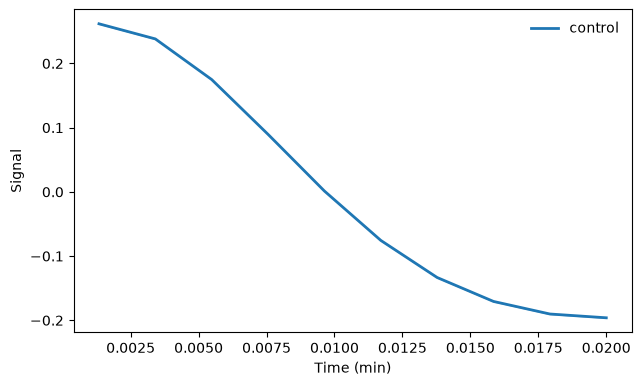

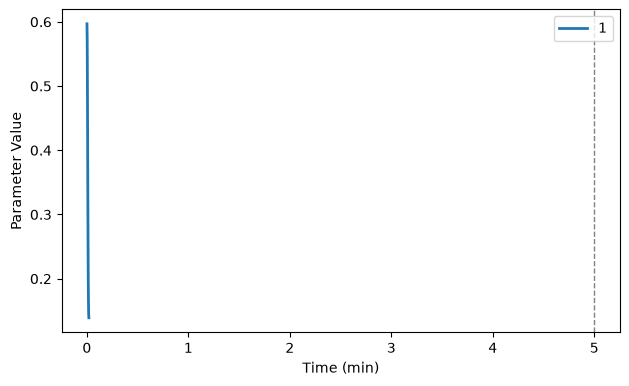

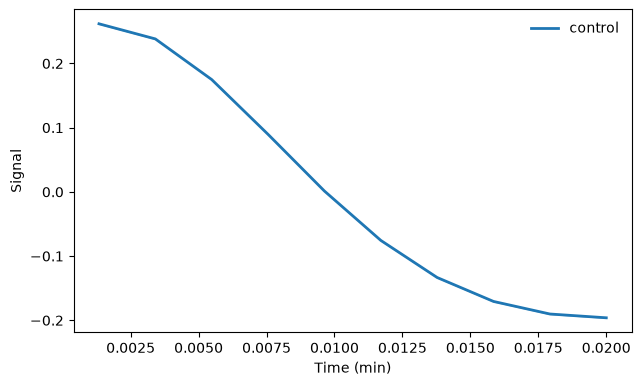

In [5]:
from matplotlib.animation import FuncAnimation, PillowWriter
from mrax.analysis.timecourse_processing import mean_timecourses_by_label, nan_gaussian_filter, apply_baseline


def plot_timecourses(image_series, label_mask, times, *, dilution=None, baseline_frames=50, smooth_sigma=2.0, labels=None, infusion_times=None, time_scale=60.0, time_unit="min", save_path=None):
    series = np.asarray(image_series, dtype=float)
    times_arr = np.asarray(times, dtype=float)
    raw_timecourses, label_values = mean_timecourses_by_label(
        series,
        label_mask,
        baseline_frames=0,
        smooth_sigma=smooth_sigma,
        dilution=dilution,
    )
    timecourses = raw_timecourses.copy()
    if baseline_frames > 0:
        for idx in range(timecourses.shape[1]):
            timecourses[:, idx] -= np.nanmean(timecourses[:baseline_frames, idx])
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    for infusion_time in infusion_times or []:
        ax.axvline(x=infusion_time, color="gray", linestyle="--", linewidth=1)
    labels = labels or {label: str(label) for label in label_values}
    for idx, label in enumerate(label_values):
        ax.plot(times_arr / time_scale, raw_timecourses[:, idx], label=labels.get(label, str(label)), linewidth=2)
    ax.set_xlabel(f"Time ({time_unit})")
    ax.set_ylabel("Parameter Value")
    ax.legend(loc="upper right")
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        plt.close(fig)
    return timecourses


def plot_mean_timecourses(timecourses, label, times, *, groups=None, infusion_times=None, vmin=None, vmax=None, label_index=0, time_scale=60.0, time_unit="min"):
    data = np.asarray(timecourses, dtype=float)
    times_arr = np.asarray(times, dtype=float)
    if data.ndim == 3 and data.shape[1] == times_arr.size:
        data = data[..., label_index][:, None, :]
    elif data.ndim == 2 and data.shape[0] == times_arr.size:
        data = data[:, label_index][None, None, :]
    group_names = list(groups) if groups is not None else [f"Group {i+1}" for i in range(data.shape[0])]
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    for infusion_time in infusion_times or []:
        ax.axvline(x=infusion_time, color="gray", linestyle="--", linewidth=1)
    for group_idx, group_name in enumerate(group_names):
        group_data = data[group_idx]
        mean_tc = np.nanmean(group_data, axis=0)
        sem_tc = np.nanstd(group_data, axis=0) / np.sqrt(max(1, group_data.shape[0]))
        line, = ax.plot(times_arr / time_scale, mean_tc, lw=2, label=group_name)
        ax.fill_between(times_arr / time_scale, mean_tc - sem_tc, mean_tc + sem_tc, color=line.get_color(), alpha=0.25)
    ax.set_xlabel(f"Time ({time_unit})")
    ax.set_ylabel(label)
    if vmin is not None or vmax is not None:
        ax.set_ylim(vmin, vmax)
    ax.legend(frameon=False, loc="upper right")
    return fig


def map_animation(image_series, reference, times, save_path, *, dilution=None, vmin=0.0, vmax=0.0005, infusion_times=None, baseline_frames=5, smooth_sigma=1.0, fps=30, dpi=300):
    series = np.asarray(image_series, dtype=float)
    if smooth_sigma and smooth_sigma > 0:
        series = nan_gaussian_filter(series, sigma=smooth_sigma)
    if dilution is not None:
        dil = apply_baseline(np.asarray(dilution, dtype=float), baseline_frames=baseline_frames, mode="divide", axis=0)
        with np.errstate(invalid="ignore", divide="ignore"):
            series = series / np.clip(dil, 1e-2, None)
    times_arr = np.asarray(times, dtype=float)
    baseline = np.nanmean(series[:baseline_frames], axis=0)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(reference, cmap="gray")
    im = ax.imshow(series[0] - baseline, vmin=vmin, vmax=vmax, cmap="jet")
    ax.axis("off")
    plt.colorbar(im, ax=ax)
    title = ax.set_title(f"t={times_arr[0]:.2f}")

    def update(frame):
        im.set_array(series[frame] - baseline)
        title.set_text(f"t={times_arr[frame]:.2f}")
        return [im, title]

    anim = FuncAnimation(fig, update, frames=series.shape[0], blit=True)
    anim.save(save_path, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)


label_mask = np.zeros(mr_image.shape[-2:], dtype=int)
label_mask[4:12, 4:12] = 1

timecourses = plot_timecourses(
    mr_image,
    label_mask,
    times=ti_vals * 1e-3,
    infusion_times=[5],
)

plot_mean_timecourses(
    timecourses[None, ...],
    label="Signal",
    times=ti_vals * 1e-3,
    groups=["control"],
    label_index=0,
)


In [6]:
animation_path = outputs_root / "roi_animation.gif"
map_animation(
    mr_image,
    reference=mr_image[0],
    times=ti_vals * 1e-3,
    save_path=str(animation_path),
)
animation_path


PosixPath('tmp/analysis_toolbox_demo/outputs/roi_animation.gif')

## Group summaries and comparisons

Use the batch output root to compare groups. Members can be study folder names
(inside ``outputs_root``) or explicit manifest paths.


In [7]:
groups = {
    "control": ["control_01", "control_02"],
    "treated": ["treated_01", "treated_02"],
}

results = analyze_groups(
    groups,
    output_root=outputs_root,
    experiment_name="t1_ir",
    rois=[roi],
    map_names=["t1"],
    stats=("mean",),
    p_adjust="fdr_bh",
)

results["group_summary"]


[{'group': 'control',
  'experiment': 't1_ir',
  'map': 't1',
  'roi': 'center',
  'stat': 'mean',
  'count': 2.0,
  'nan_count': 0.0,
  'mean': 2452.281494140625,
  'variance': 0.003567814826965332,
  'std': 0.05973118805921519,
  'sem': 0.04223632812499999,
  'median': 2452.281494140625,
  'min': 2452.2392578125,
  'max': 2452.32373046875,
  'p25': 2452.2603759765625,
  'p75': 2452.3026123046875,
  'unit': 'ms'},
 {'group': 'treated',
  'experiment': 't1_ir',
  'map': 't1',
  'roi': 'center',
  'stat': 'mean',
  'count': 2.0,
  'nan_count': 0.0,
  'mean': 2454.6890869140625,
  'variance': 0.08044984936714172,
  'std': 0.28363682653552186,
  'sem': 0.20056152343749997,
  'median': 2454.6890869140625,
  'min': 2454.488525390625,
  'max': 2454.8896484375,
  'p25': 2454.5888061523438,
  'p75': 2454.7893676757812,
  'unit': 'ms'}]

In [8]:
results["comparisons"]


[{'experiment': 't1_ir',
  'map': 't1',
  'roi': 'center',
  'stat': 'mean',
  'group_a': 'control',
  'group_b': 'treated',
  'n_a': 2.0,
  'n_b': 2.0,
  'mean_a': 2452.281494140625,
  'mean_b': 2454.68896484375,
  'mean_diff': -2.407470703125,
  't_stat': -11.746614794850906,
  't_p': 0.04431433472445087,
  'effect_size_d': -11.746614794850906,
  'effect_size_g': -6.712351311343374,
  'np_test': 'mannwhitney',
  'np_stat': 0.0,
  'np_p': 0.3333333333333333,
  'unit': 'ms',
  't_p_fdr_bh': 0.04431433472445087}]

## Plot group distributions and significance

Visualize per-subject distributions and group summaries with significance markers.


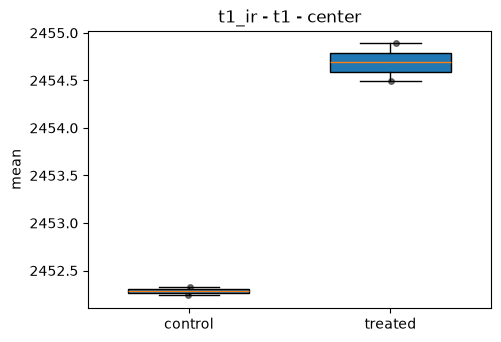

In [9]:
def _grouped_values(rows, *, experiment, map_name, roi, stat):
    grouped = {}
    for row in rows:
        if row.get("experiment") == experiment and row.get("map") == map_name and row.get("roi") == roi and row.get("stat") == stat:
            grouped.setdefault(str(row.get("group")), []).append(float(row.get("value", np.nan)))
    return grouped


def _significance_label(p_value):
    if p_value is None or not np.isfinite(p_value):
        return "n/a"
    if p_value <= 0.001:
        return "***"
    if p_value <= 0.01:
        return "**"
    if p_value <= 0.05:
        return "*"
    return "n.s."


def plot_group_distributions(subject_rows, *, experiment, map_name, roi, stat, comparisons=None, kind="box"):
    grouped = _grouped_values(subject_rows, experiment=experiment, map_name=map_name, roi=roi, stat=stat)
    order = sorted(grouped)
    values = [grouped[name] for name in order]
    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    positions = np.arange(len(order))
    if kind == "violin":
        ax.violinplot(values, positions=positions, showmedians=True)
    else:
        ax.boxplot(values, positions=positions, widths=0.6, patch_artist=True)
    rng = np.random.default_rng(0)
    for idx, group_vals in enumerate(values):
        ax.scatter(np.full(len(group_vals), positions[idx]) + rng.normal(0, 0.04, len(group_vals)), group_vals, s=16, color="#2f2f2f", alpha=0.65)
    ax.set_xticks(positions)
    ax.set_xticklabels(order)
    ax.set_ylabel(stat)
    ax.set_title(f"{experiment} - {map_name} - {roi}")
    return fig


def plot_group_summary(summary_rows, *, experiment, map_name, roi, stat, comparisons=None, value_key="mean", error_key="sem"):
    rows = [row for row in summary_rows if row.get("experiment") == experiment and row.get("map") == map_name and row.get("roi") == roi and row.get("stat") == stat]
    order = sorted(str(row.get("group")) for row in rows)
    by_group = {str(row.get("group")): row for row in rows}
    means = [float(by_group[group].get(value_key, np.nan)) for group in order]
    errors = [float(by_group[group].get(error_key, np.nan)) for group in order]
    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    positions = np.arange(len(order))
    ax.bar(positions, means, yerr=errors, capsize=4, color="#88aadd", alpha=0.8)
    ax.set_xticks(positions)
    ax.set_xticklabels(order)
    ax.set_ylabel(f"{value_key} ({stat})")
    ax.set_title(f"{experiment} - {map_name} - {roi}")
    return fig


fig = plot_group_distributions(
    results["subject_stats"],
    comparisons=results["comparisons"],
    experiment="t1_ir",
    map_name="t1",
    roi="center",
    stat="mean",
    kind="box",
)
plt.show()


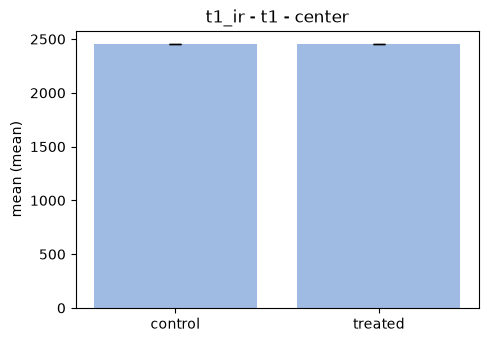

In [10]:
fig = plot_group_summary(
    results["group_summary"],
    comparisons=results["comparisons"],
    experiment="t1_ir",
    map_name="t1",
    roi="center",
    stat="mean",
)
plt.show()
